# Airline Passenger Satisfaction: Binary Logistic Regression

**Question.** Which passengers leave satisfied, and which parts of the journey drive that outcome?

**Approach.** An interpretable binary logistic regression, read through odds ratios with confidence intervals. It is compared with a reduced (optimised) model and benchmarked against a non-linear model.

**Notebook structure**
1. Dataset and business problem
2. Exploratory data analysis
3. Data preparation
4. Complete model and interpretation
5. Optimised model
6. Extensions: cost of linearity, where it comes from, categorical encoding, controllable drivers
7. Conclusion

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

RANDOM_STATE = 42
DATA_PATH = Path('../data/airline.csv')
FIG_DIR, MET_DIR = Path('../outputs/figures'), Path('../outputs/metrics')
FIG_DIR.mkdir(parents=True, exist_ok=True); MET_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110})

---
## 1. Dataset and Business Problem

An airline wants to know **which passengers walk away satisfied** and **which service levers move that outcome**. The target is binary: `satisfaction` is 1 = *satisfied* and 0 = *neutral or dissatisfied*.

| Family | Columns |
|---|---|
| Passenger / trip | Gender, Customer Type, Age, Type of Travel, Class, Flight Distance |
| Service ratings (1-5; **0 = not applicable**) | 14 items, from inflight wifi to cleanliness |
| Operational | Departure and arrival delay (minutes) |

**Framing caveat.** Service ratings are collected in the same post-flight survey as the satisfaction label. The model therefore explains satisfaction (a *driver analysis*); it is not a tool for predicting satisfaction before a flight.

In [2]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.drop(columns=['Unnamed: 0', 'id'])
print('Shape:', df.shape, '| duplicate rows:', df.duplicated().sum())
display(df.head(3))

Shape: (25976, 23) | duplicate rows: 0


,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Female,Loyal Customer,52,Business travel,Eco,160,5,4,3,4,3,4,3,5,5,5,5,2,5,5,50,44.0,satisfied
1,Female,Loyal Customer,36,Business travel,Business,2863,1,1,3,1,5,4,5,4,4,4,4,3,4,5,0,0.0,satisfied
2,Male,disloyal Customer,20,Business travel,Eco,192,2,0,2,4,2,2,2,2,4,1,3,2,2,2,0,0.0,neutral or dissatisfied


---
## 2. Exploratory Data Analysis

In [3]:
missing = df.isna().sum()
print('Missing values:\n', missing[missing > 0].to_string())
target_share = df['satisfaction'].value_counts(normalize=True).round(3)
print('\nTarget balance:\n', target_share.to_string())

Missing values:
 Arrival Delay in Minutes    83

Target balance:
 satisfaction
neutral or dissatisfied    0.561
satisfied                  0.439


**Observation:** 25,976 passengers, no duplicate rows, and 83 missing arrival-delay values. The classes are reasonably balanced (56.1% neutral or dissatisfied, 43.9% satisfied), so accuracy is a usable headline metric. Precision, recall and specificity are still reported.

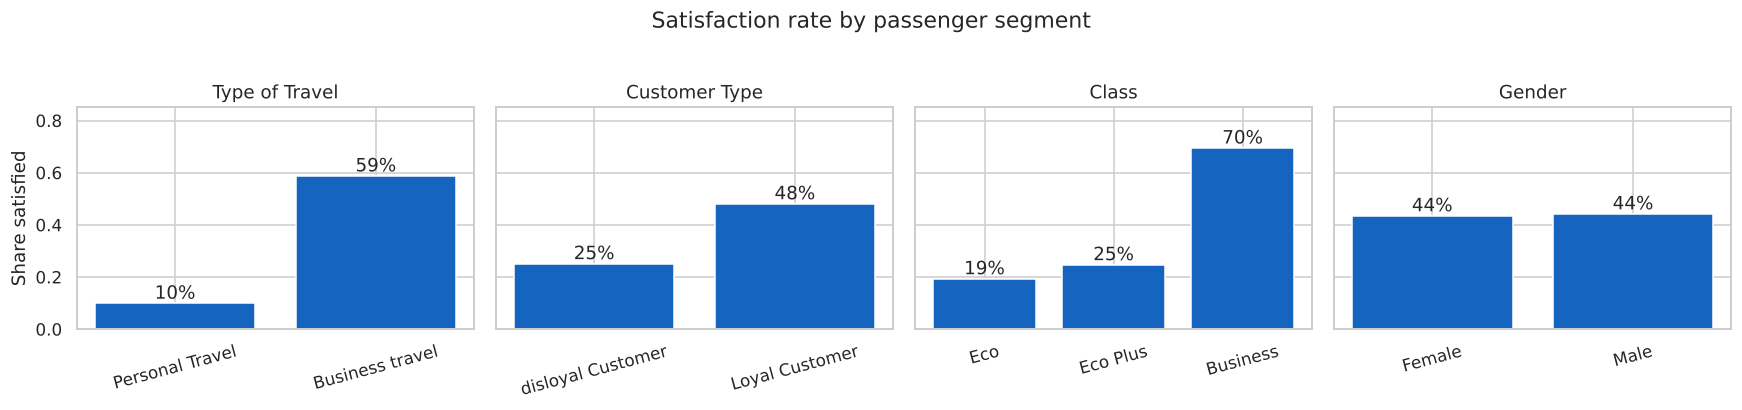

In [4]:
sat = (df['satisfaction'] == 'satisfied')
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, col in zip(axes, ['Type of Travel', 'Customer Type', 'Class', 'Gender']):
    rate = sat.groupby(df[col]).mean().sort_values()
    bars = ax.bar(rate.index, rate.values, color='#1565C0')
    ax.bar_label(bars, labels=[f'{v:.0%}' for v in rate.values])
    ax.set_title(col); ax.tick_params(axis='x', labelrotation=15)
axes[0].set_ylabel('Share satisfied'); axes[0].set_ylim(0, 0.85)
plt.suptitle('Satisfaction rate by passenger segment', y=1.03)
plt.tight_layout(); plt.savefig(FIG_DIR / 'satisfaction_by_segment.png', bbox_inches='tight'); plt.show()

**Observation:** Segment differences are large. Business travellers are satisfied 59% of the time against 10% for personal travellers. Loyal customers are satisfied 48% of the time against 25% for disloyal ones. Business class reaches 70%, against 19% for Economy and 25% for Economy Plus. Gender makes no difference (44% for both).

In [5]:
RATING_COLS = ['Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
               'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment',
               'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service',
               'Inflight service', 'Cleanliness']
zero_check = pd.DataFrame({
    'Zero (N/A) count': (df[RATING_COLS] == 0).sum(),
    'Share satisfied when 0': [sat[df[c] == 0].mean() if (df[c] == 0).any() else np.nan for c in RATING_COLS],
    'Share satisfied when 1-5': [sat[df[c] > 0].mean() for c in RATING_COLS]}).round(3)
display(zero_check[zero_check['Zero (N/A) count'] > 0])

,Zero (N/A) count,Share satisfied when 0,Share satisfied when 1-5
Inflight wifi service,813,0.998,0.421
Departure/Arrival time convenient,1381,0.503,0.435
Ease of Online booking,1195,0.671,0.428
Food and drink,25,0.200,0.439
Online boarding,652,0.595,0.435
Inflight entertainment,4,0.000,0.439
On-board service,2,0.000,0.439
Leg room service,126,0.317,0.440
Inflight service,2,0.000,0.439
Cleanliness,2,0.000,0.439


**Observation:** A rating of 0 means *not applicable*, and it behaves very differently from a low score. The 813 passengers with inflight wifi = 0 are 99.8% satisfied, against 42.1% for those who gave a 1-5 rating. Left as a numeric 0, these passengers would be read as having rated wifi worse than 1 and would distort the wifi coefficient. They are recoded as missing, with an indicator column where N/A is common.

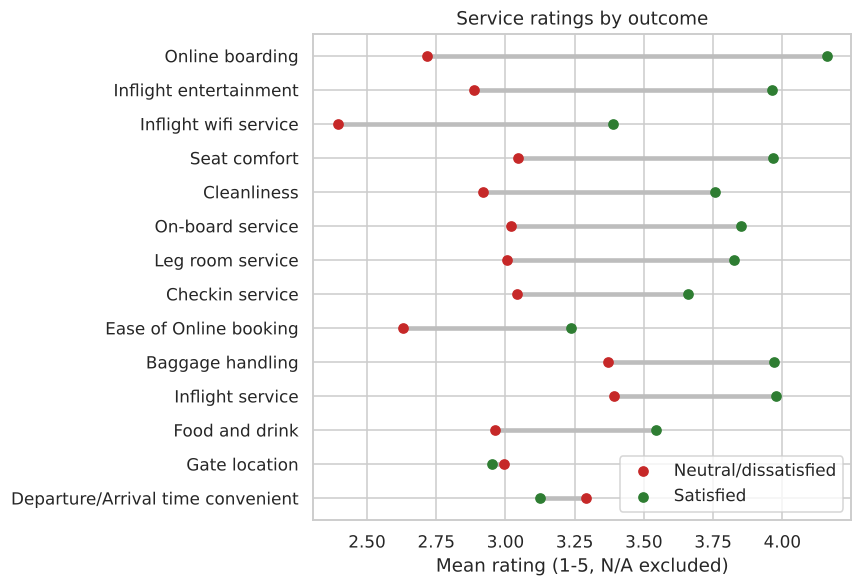

In [6]:
rating_gap = (df[RATING_COLS].replace(0, np.nan).groupby(sat).mean().T
              .rename(columns={False: 'Neutral/dissatisfied', True: 'Satisfied'}))
rating_gap['Gap'] = rating_gap['Satisfied'] - rating_gap['Neutral/dissatisfied']
rating_gap = rating_gap.sort_values('Gap')
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.hlines(rating_gap.index, rating_gap['Neutral/dissatisfied'], rating_gap['Satisfied'], color='#BDBDBD', lw=3)
ax.scatter(rating_gap['Neutral/dissatisfied'], rating_gap.index, color='#C62828', label='Neutral/dissatisfied', zorder=3)
ax.scatter(rating_gap['Satisfied'], rating_gap.index, color='#2E7D32', label='Satisfied', zorder=3)
ax.set_xlabel('Mean rating (1-5, N/A excluded)'); ax.set_title('Service ratings by outcome'); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(FIG_DIR / 'service_rating_gap.png', bbox_inches='tight'); plt.show()

**Observation:** Online boarding shows the largest gap between satisfied and other passengers (about 4.1 vs 2.7), followed by inflight entertainment, wifi and seat comfort. Two items run the other way or are flat: departure/arrival time convenience is rated *lower* by satisfied passengers, and gate location barely differs.

Share of flights with zero departure delay: 56.5%
Skewness: {'Departure Delay in Minutes': 7.2, 'Arrival Delay in Minutes': 7.0}


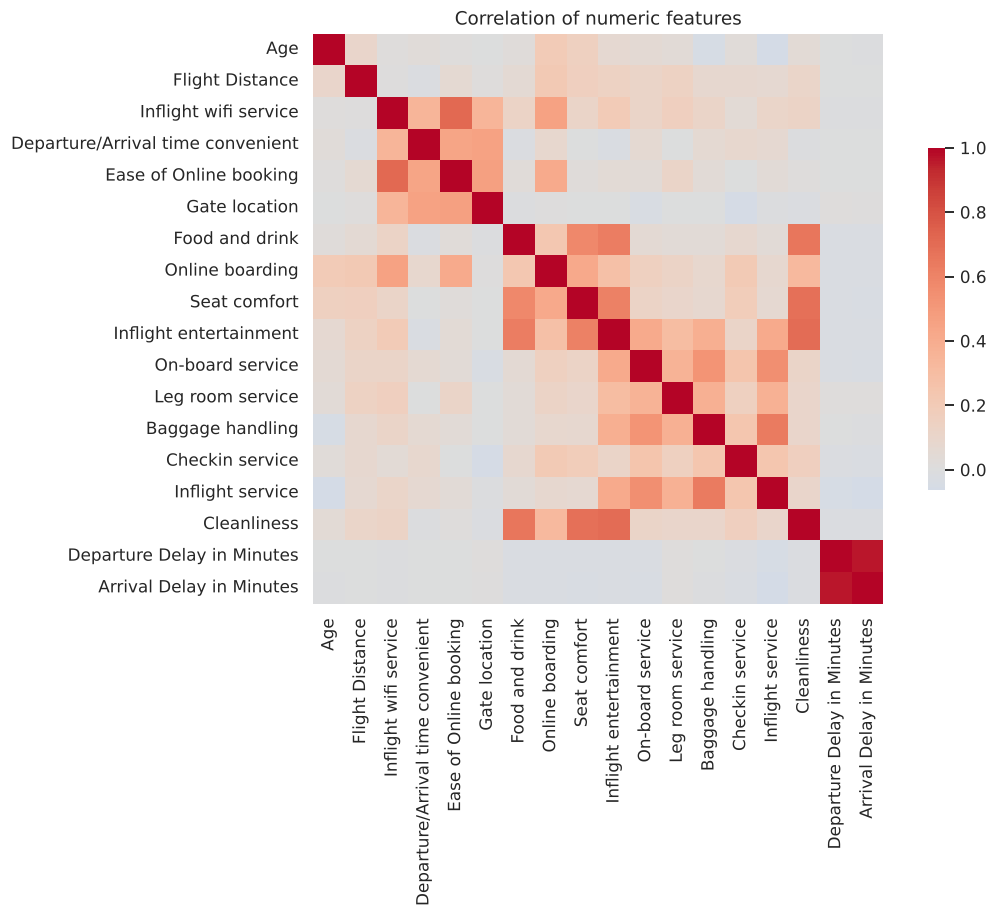

,level_0,level_1,r,abs_r
305,Departure Delay in Minutes,Arrival Delay in Minutes,0.965,0.965
40,Inflight wifi service,Ease of Online booking,0.711,0.711
177,Inflight entertainment,Cleanliness,0.695,0.695
159,Seat comfort,Cleanliness,0.684,0.684
123,Food and drink,Cleanliness,0.659,0.659
230,Baggage handling,Inflight service,0.632,0.632


In [7]:
DELAY_COLS = ['Departure Delay in Minutes', 'Arrival Delay in Minutes']
print('Share of flights with zero departure delay: {:.1%}'.format((df[DELAY_COLS[0]] == 0).mean()))
print('Skewness:', df[DELAY_COLS].skew().round(1).to_dict())
num_all = df.select_dtypes(include=np.number)
plt.figure(figsize=(11, 8.5))
sns.heatmap(num_all.corr(), cmap='coolwarm', center=0, square=True, cbar_kws={'shrink': 0.6})
plt.title('Correlation of numeric features')
plt.tight_layout(); plt.savefig(FIG_DIR / 'correlation_heatmap.png', bbox_inches='tight'); plt.show()
corr_pairs = (num_all.corr().where(np.triu(np.ones((num_all.shape[1],) * 2), k=1).astype(bool))
              .stack().rename('r').reset_index().assign(abs_r=lambda d: d['r'].abs())
              .sort_values('abs_r', ascending=False).head(6))
display(corr_pairs.round(3))

**Observation:** Departure and arrival delays are almost the same variable (r = 0.965). Both are extremely skewed (skewness about 7, with 56.5% of flights having zero departure delay), so a `log1p` transform is applied. Inflight wifi and ease of online booking correlate at 0.71 on the raw data, which includes the N/A zeros.

---
## 3. Data Preparation

1. Map the target to 1 (satisfied) / 0 (neutral or dissatisfied).
2. Recode rating = 0 (*not applicable*) as missing. Imputation adds a missing-indicator column so the information is kept but is no longer treated as a "very low" score.
3. Stratified 80/20 split **before** any fitted transformation, to avoid leakage.
4. A `Pipeline` wraps every step: `log1p` for the heavily skewed delays, median imputation, standard scaling, and one-hot encoding (first level dropped) for the categoricals. Because the pipeline is fitted on training folds only, cross-validation stays leak-free.

In [8]:
data = df.copy()
data['satisfaction'] = (data['satisfaction'] == 'satisfied').astype(int)
data[RATING_COLS] = data[RATING_COLS].replace(0, np.nan)

CAT_COLS = ['Gender', 'Customer Type', 'Type of Travel', 'Class']
NUM_COLS = ['Age', 'Flight Distance']
# Missing indicators only where N/A is common enough to estimate (>= 100 rows); the handful of
# N/A values in other ratings (2-25 rows) are median-imputed without an indicator.
NA_COLS = [c for c in RATING_COLS if (df[c] == 0).sum() >= 100]
print('Ratings with a missing indicator:', NA_COLS)

X = data.drop(columns='satisfaction'); y = data['satisfaction']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape[0]:,} rows | Test: {X_test.shape[0]:,} rows | satisfied share train/test: '
      f'{y_train.mean():.3f} / {y_test.mean():.3f}')

def make_preprocessor(num_cols, rating_cols, delay_cols, cat_cols):
    parts = [('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_cols),
             ('rating_na', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)),
                                     ('scale', StandardScaler())]), [c for c in rating_cols if c in NA_COLS]),
             ('rating', Pipeline([('impute', SimpleImputer(strategy='median')),
                                  ('scale', StandardScaler())]), [c for c in rating_cols if c not in NA_COLS]),
             ('delay', Pipeline([('impute', SimpleImputer(strategy='median')), ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                                 ('scale', StandardScaler())]), delay_cols),
             ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)]
    return ColumnTransformer([p for p in parts if p[2]], verbose_feature_names_out=False)

def make_model(rating_cols=RATING_COLS, delay_cols=DELAY_COLS):
    return Pipeline([('prep', make_preprocessor(NUM_COLS, rating_cols, delay_cols, CAT_COLS)),
                     ('clf', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])

Ratings with a missing indicator: ['Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Online boarding', 'Leg room service']
Train: 20,780 rows | Test: 5,196 rows | satisfied share train/test: 0.439 / 0.439


---
## 4. Complete Model and Interpretation

Logistic regression models the log-odds of satisfaction:

$$\ln\frac{p}{1-p} = \beta_0 + \beta_1x_1 + \dots + \beta_kx_k$$

$e^{\beta}$ is the **odds ratio**: the multiplicative change in the odds of being satisfied for a one-unit increase in a feature. Numeric inputs are standardised, so one unit is **one standard deviation**. For a dummy variable, it is the change relative to the dropped reference level.

Features after encoding: 28
5-fold CV (train): {'Accuracy': '0.904 +/- 0.005', 'F1': '0.890 +/- 0.006', 'ROC-AUC': '0.966 +/- 0.003'}


,Complete model - test
Accuracy,0.903
Precision,0.882
Recall (satisfied),0.900
Specificity (dissatisfied caught),0.906
F1,0.891
ROC-AUC,0.966


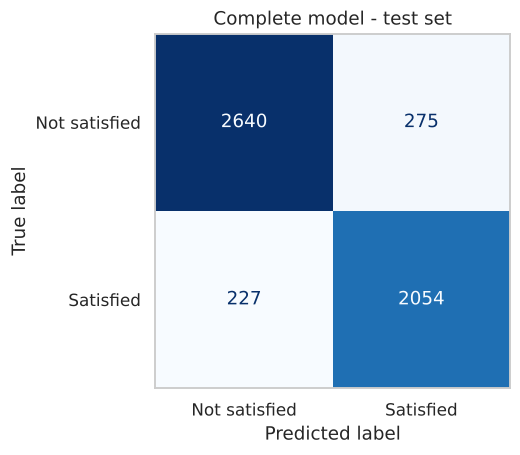

In [9]:
def metrics(y_true, y_pred, y_prob):
    return {'Accuracy': accuracy_score(y_true, y_pred), 'Precision': precision_score(y_true, y_pred),
            'Recall (satisfied)': recall_score(y_true, y_pred),
            'Specificity (dissatisfied caught)': recall_score(y_true, y_pred, pos_label=0),
            'F1': f1_score(y_true, y_pred), 'ROC-AUC': roc_auc_score(y_true, y_prob)}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
CV_SCORING = {'Accuracy': 'accuracy', 'F1': 'f1', 'ROC-AUC': 'roc_auc'}
def cv_summary(model, Xd=X_train):
    r = cross_validate(model, Xd, y_train, cv=cv, scoring=CV_SCORING, n_jobs=-1)
    return {k: f"{r['test_' + k].mean():.3f} +/- {r['test_' + k].std():.3f}" for k in CV_SCORING}

complete = make_model().fit(X_train, y_train)
comp_pred, comp_prob = complete.predict(X_test), complete.predict_proba(X_test)[:, 1]
comp_test = metrics(y_test, comp_pred, comp_prob)
comp_cv = cv_summary(make_model())
print('Features after encoding:', len(complete[:-1].get_feature_names_out()))
print('5-fold CV (train):', comp_cv)
display(pd.Series(comp_test, name='Complete model - test').round(3).to_frame())

fig, ax = plt.subplots(figsize=(5, 4.3))
ConfusionMatrixDisplay(confusion_matrix(y_test, comp_pred), display_labels=['Not satisfied', 'Satisfied']).plot(
    ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Complete model - test set'); ax.grid(False)
plt.tight_layout(); plt.savefig(FIG_DIR / 'confusion_complete.png', bbox_inches='tight'); plt.show()

**Observation:** The complete model is stable across folds (CV accuracy 0.904 ± 0.005, ROC-AUC 0.966 ± 0.003) and matches on the test set: accuracy 0.903, precision 0.882, recall 0.900, specificity 0.906. Errors are evenly split between 275 false positives and 227 false negatives.

### Odds ratios with 95% confidence intervals
scikit-learn's `LogisticRegression` applies a mild L2 penalty by default and does not report uncertainty. To read coefficients with standard errors, the same preprocessed training matrix is refitted as an unpenalised `statsmodels` Logit.

In [10]:
feat_names = complete[:-1].get_feature_names_out()
Xt_train = pd.DataFrame(complete[:-1].transform(X_train), columns=feat_names, index=X_train.index)
logit = sm.Logit(y_train, sm.add_constant(Xt_train)).fit(disp=0, maxiter=200)
ci = logit.conf_int()
or_table = pd.DataFrame({'Coef (log-odds)': logit.params, 'Odds ratio': np.exp(logit.params),
                         'OR 2.5%': np.exp(ci[0]), 'OR 97.5%': np.exp(ci[1]), 'p-value': logit.pvalues}).drop('const')
or_table = or_table.reindex(or_table['Coef (log-odds)'].abs().sort_values(ascending=False).index)
print(f'McFadden pseudo R-squared: {logit.prsquared:.3f}')
display(or_table.round(3))
or_table.round(4).to_csv(MET_DIR / 'odds_ratios_complete.csv')


McFadden pseudo R-squared: 0.659


,Coef (log-odds),Odds ratio,OR 2.5%,OR 97.5%,p-value
Type of Travel_Personal Travel,-3.483,0.031,0.026,0.037,0.000
Customer Type_disloyal Customer,-2.702,0.067,0.057,0.080,0.000
missingindicator_Inflight wifi service,1.530,4.620,3.502,6.096,0.000
Online boarding,1.196,3.308,3.069,3.566,0.000
Inflight wifi service,1.130,3.096,2.857,3.356,0.000
Class_Eco Plus,-0.993,0.370,0.296,0.463,0.000
Class_Eco,-0.758,0.469,0.408,0.539,0.000
Departure/Arrival time convenient,-0.519,0.595,0.551,0.643,0.000
Checkin service,0.501,1.651,1.559,1.748,0.000
On-board service,0.421,1.524,1.420,1.634,0.000


**Observation:** The model explains a large share of the variation (McFadden pseudo R² = 0.659). The two strongest effects are segments: personal travel (OR 0.031, roughly 32x lower odds of satisfaction) and disloyal customers (OR 0.067). Among service items, a one-SD better online-boarding rating multiplies the odds by 3.3, and wifi by 3.1. Departure/arrival time convenience (OR 0.60) and gate location (OR 0.71) have *negative* conditional effects. That matches the EDA, but it is not a plausible causal direction, so these two should not be read as levers.

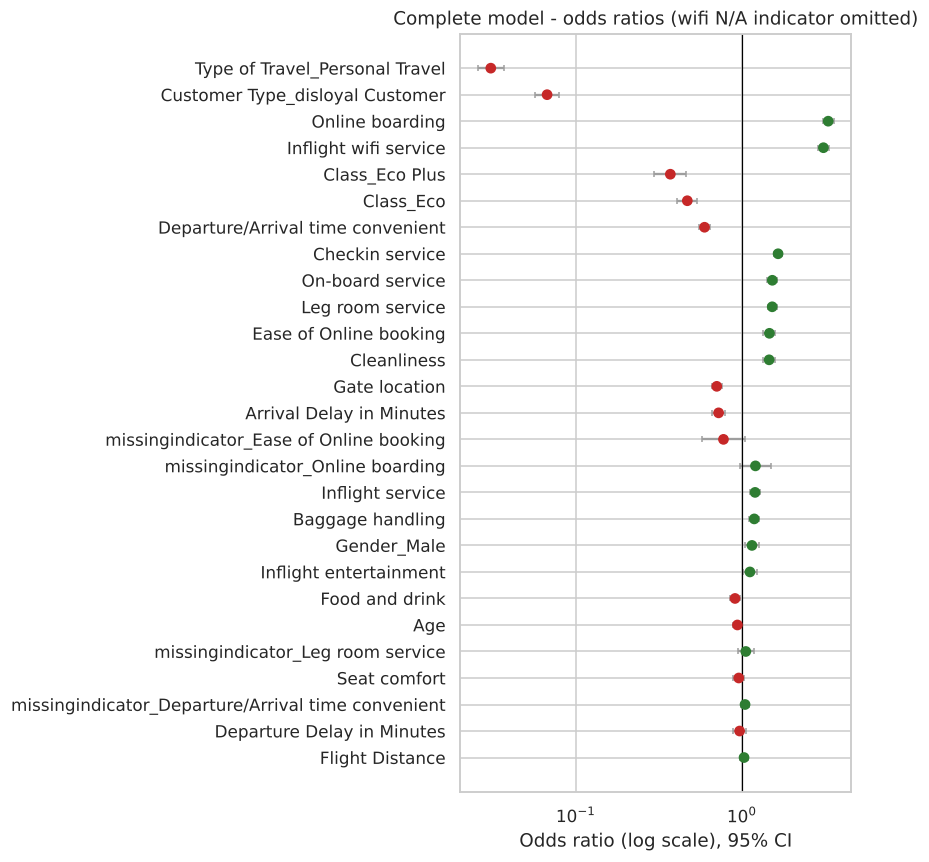

In [11]:
# The wifi N/A indicator is near-separating (811 of 813 satisfied); its odds ratio is reported in
# the table but left off the chart so it does not compress the scale for everything else.
plot_df = or_table.drop(index='missingindicator_Inflight wifi service').iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 8))
colors = ['#2E7D32' if v > 1 else '#C62828' for v in plot_df['Odds ratio']]
ax.errorbar(plot_df['Odds ratio'], plot_df.index,
            xerr=[plot_df['Odds ratio'] - plot_df['OR 2.5%'], plot_df['OR 97.5%'] - plot_df['Odds ratio']],
            fmt='none', ecolor='#9E9E9E', capsize=2)
ax.scatter(plot_df['Odds ratio'], plot_df.index, c=colors, zorder=3)
ax.axvline(1, color='black', lw=0.8); ax.set_xscale('log')
ax.set_xlabel('Odds ratio (log scale), 95% CI'); ax.set_title('Complete model - odds ratios (wifi N/A indicator omitted)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'odds_ratios_complete.png', bbox_inches='tight'); plt.show()

---
## 5. Optimised Model

**Two-step rule.**
1. For any pair of numeric predictors with |r| > 0.7, keep the one more strongly correlated with the target and drop the other.
2. Compute variance inflation factors (VIF) on the encoded design matrix. While any rating, numeric or delay feature has VIF > 5, drop the highest and recompute.

In [12]:
THRESH = 0.7
num_pred = data[NUM_COLS + RATING_COLS + DELAY_COLS].loc[X_train.index]
target_corr = num_pred.corrwith(y_train).abs()
corr = num_pred.corr().abs()
to_drop = set()
for i, a in enumerate(corr.columns):
    for b in corr.columns[i + 1:]:
        if corr.loc[a, b] > THRESH and a not in to_drop and b not in to_drop:
            weaker = a if target_corr[a] < target_corr[b] else b
            to_drop.add(weaker)
            print(f'|r|({a}, {b}) = {corr.loc[a, b]:.2f} -> drop {weaker} '
                  f'(|r| with target {target_corr[weaker]:.2f} vs {target_corr[b if weaker == a else a]:.2f})')

opt_ratings = [c for c in RATING_COLS if c not in to_drop]
opt_delays = [c for c in DELAY_COLS if c not in to_drop]
def vif_table(ratings, delays):
    pre = make_preprocessor(NUM_COLS, ratings, delays, CAT_COLS).fit(X_train)
    Xt = np.column_stack([np.ones(len(X_train)), pre.transform(X_train)])
    return pd.Series([variance_inflation_factor(Xt, i + 1) for i in range(Xt.shape[1] - 1)],
                     index=pre.get_feature_names_out())

while True:
    vif = vif_table(opt_ratings, opt_delays)
    candidates = vif[[c for c in vif.index if c in NUM_COLS + opt_ratings + opt_delays]]
    if candidates.max() <= 5:
        break
    worst = candidates.idxmax()
    print(f'VIF({worst}) = {candidates.max():.2f} > 5 -> drop')
    opt_ratings = [c for c in opt_ratings if c != worst]; opt_delays = [c for c in opt_delays if c != worst]
print(f'\nMax VIF after removal: {vif.max():.2f} ({vif.idxmax()})')
print('Dropped overall:', sorted(set(RATING_COLS + DELAY_COLS) - set(opt_ratings + opt_delays)))
display(vif.sort_values(ascending=False).head(5).round(2).to_frame('VIF'))

|r|(Departure Delay in Minutes, Arrival Delay in Minutes) = 0.96 -> drop Departure Delay in Minutes (|r| with target 0.05 vs 0.06)



Max VIF after removal: 6.42 (missingindicator_Ease of Online booking)
Dropped overall: ['Departure Delay in Minutes']


,VIF
missingindicator_Ease of Online booking,6.42
Inflight entertainment,3.93
missingindicator_Inflight wifi service,3.08
Cleanliness,2.88
missingindicator_Online boarding,2.82


**Observation:** Only departure delay is removed (r = 0.96 with arrival delay, and slightly weaker correlation with the target). Once N/A zeros are excluded, wifi and online booking correlate below 0.7, and no substantive feature has VIF above 5. The highest VIF (6.4) belongs to the *ease-of-booking N/A indicator*, which overlaps with the wifi N/A indicator. It is kept, because it marks missingness rather than a rating.

In [13]:
optimised = make_model(opt_ratings, opt_delays).fit(X_train, y_train)
opt_pred, opt_prob = optimised.predict(X_test), optimised.predict_proba(X_test)[:, 1]
opt_test = metrics(y_test, opt_pred, opt_prob)
opt_cv = cv_summary(make_model(opt_ratings, opt_delays))

comparison = pd.DataFrame({'Complete': comp_test, 'Optimised': opt_test}).round(3)
comparison.loc['Encoded features'] = [len(complete[:-1].get_feature_names_out()), len(optimised[:-1].get_feature_names_out())]
display(comparison)
display(pd.DataFrame({'Complete': comp_cv, 'Optimised': opt_cv}).rename_axis('5-fold CV (train)'))
comparison.to_csv(MET_DIR / 'complete_vs_optimised_test.csv')

,Complete,Optimised
Accuracy,0.903,0.903
Precision,0.882,0.881
Recall (satisfied),0.900,0.900
Specificity (dissatisfied caught),0.906,0.905
F1,0.891,0.890
ROC-AUC,0.966,0.966
Encoded features,28.000,27.000


,Complete,Optimised
5-fold CV (train),,
Accuracy,0.904 +/- 0.005,0.903 +/- 0.004
F1,0.890 +/- 0.006,0.890 +/- 0.005
ROC-AUC,0.966 +/- 0.003,0.966 +/- 0.003


**Observation:** Dropping departure delay changes nothing measurable (test accuracy 0.903 for both, identical CV scores). The optimised model is preferred because it is simpler and its delay coefficient is no longer split across two near-identical inputs.

---
## 6. Extensions

### 6A. What does linearity cost?
A gradient-boosted tree model (`HistGradientBoostingClassifier`, default settings) uses the same inputs. The gap between the two models shows how much signal is non-linear or comes from interactions that the logistic model cannot represent.

In [14]:
hgb = Pipeline([('prep', make_preprocessor(NUM_COLS, opt_ratings, opt_delays, CAT_COLS)),
                ('clf', HistGradientBoostingClassifier(random_state=RANDOM_STATE))]).fit(X_train, y_train)
hgb_pred, hgb_prob = hgb.predict(X_test), hgb.predict_proba(X_test)[:, 1]
bench = pd.DataFrame({'Logistic (optimised)': opt_test, 'Gradient boosting': metrics(y_test, hgb_pred, hgb_prob)}).round(3)
display(bench)
bench.to_csv(MET_DIR / 'logistic_vs_boosting_test.csv')

,Logistic (optimised),Gradient boosting
Accuracy,0.903,0.962
Precision,0.881,0.966
Recall (satisfied),0.900,0.947
Specificity (dissatisfied caught),0.905,0.974
F1,0.890,0.956
ROC-AUC,0.966,0.994


**Observation:** A default gradient-boosting model reaches 0.962 accuracy and 0.994 ROC-AUC, against 0.903 and 0.966 for the logistic model. Its specificity is 0.974 against 0.905. Six points of accuracy is too large to be noise, so a substantial part of the signal is non-linear.

### 6B. Where the non-linearity comes from
The satisfaction rate is cross-tabulated by inflight-wifi rating and travel type.

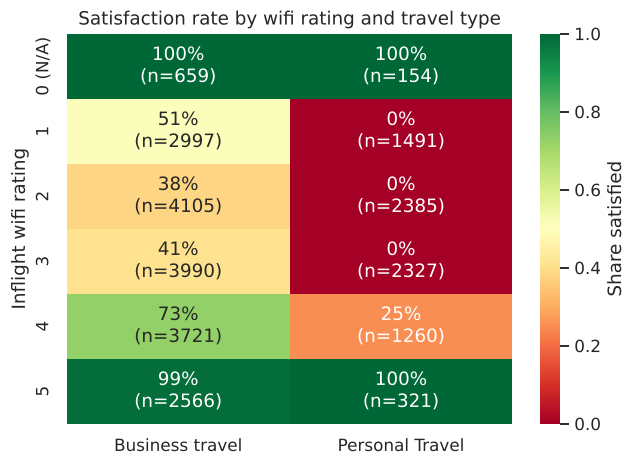

Type of Travel,Business travel,Personal Travel
0 (N/A),0.997,1.000
1,0.508,0.000
2,0.382,0.000
3,0.407,0.000
4,0.728,0.252
5,0.986,1.000


In [15]:
wifi_tab = pd.crosstab(df['Inflight wifi service'], df['Type of Travel'], values=sat, aggfunc='mean')
wifi_n = pd.crosstab(df['Inflight wifi service'], df['Type of Travel'])
wifi_tab.index = ['0 (N/A)', '1', '2', '3', '4', '5']; wifi_n.index = wifi_tab.index
labels = wifi_tab.map(lambda v: f'{v:.0%}') + '\n(n=' + wifi_n.astype(str) + ')'
fig, ax = plt.subplots(figsize=(6, 4.4))
sns.heatmap(wifi_tab, annot=labels, fmt='', cmap='RdYlGn', vmin=0, vmax=1, cbar_kws={'label': 'Share satisfied'}, ax=ax)
ax.set_ylabel('Inflight wifi rating'); ax.set_xlabel(''); ax.set_title('Satisfaction rate by wifi rating and travel type')
plt.tight_layout(); plt.savefig(FIG_DIR / 'wifi_by_travel_type.png', bbox_inches='tight'); plt.show()
display(wifi_tab.round(3))

**Observation:** The non-linearity is a step. Personal travellers who rate wifi 1, 2 or 3 are **never** satisfied (0 of 6,203). At a rating of 4, 25% are satisfied. At 5 or N/A, all are. Business travellers follow a softer version (38-51% at ratings 1-3, 99% at 5). A linear term in the wifi rating cannot express 'nothing changes until 4, then everything does'. A pattern this clean is unusual in real survey data and suggests the label may be partly rule-generated, so these drivers describe *this dataset* rather than airline passengers in general.

### 6C. Can logistic regression recover the gap?
Logistic regression is linear in its inputs, not necessarily in the raw ratings. Encoding each rating as a categorical variable (one dummy per level, with N/A as its own level) lets the model learn step-shaped effects such as "only a 4 or 5 counts" while staying interpretable.

Encoded features: 74
5-fold CV (train): {'Accuracy': '0.933 +/- 0.005', 'F1': '0.922 +/- 0.006', 'ROC-AUC': '0.979 +/- 0.002'}


,Logistic - ratings linear,Logistic - ratings categorical,Gradient boosting
Accuracy,0.903,0.934,0.962
Precision,0.881,0.927,0.966
Recall (satisfied),0.900,0.924,0.947
Specificity (dissatisfied caught),0.905,0.943,0.974
F1,0.890,0.925,0.956
ROC-AUC,0.966,0.979,0.994


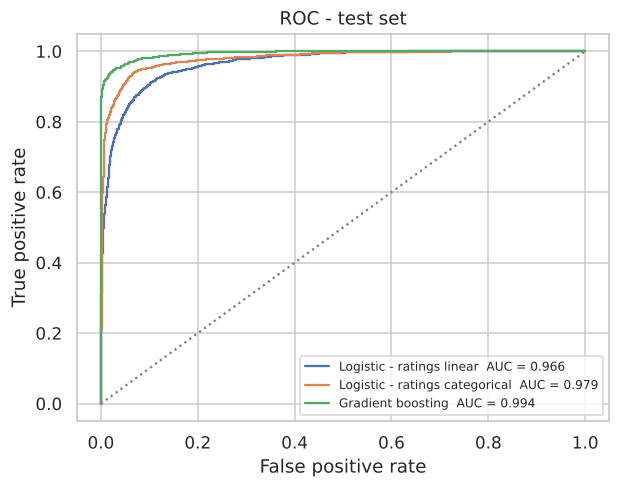

In [16]:
cat_pre = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), NUM_COLS),
    ('delay', Pipeline([('impute', SimpleImputer(strategy='median')),
                        ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                        ('scale', StandardScaler())]), opt_delays),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), CAT_COLS + opt_ratings)])
X_train_c, X_test_c = X_train.copy(), X_test.copy()
X_train_c[opt_ratings] = X_train_c[opt_ratings].fillna(0).astype(int)   # 0 = N/A becomes its own level
X_test_c[opt_ratings] = X_test_c[opt_ratings].fillna(0).astype(int)
cat_model = Pipeline([('prep', cat_pre), ('clf', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))])
cat_model.fit(X_train_c, y_train)
cat_pred, cat_prob = cat_model.predict(X_test_c), cat_model.predict_proba(X_test_c)[:, 1]
r = cross_validate(cat_model, X_train_c, y_train, cv=cv, scoring=CV_SCORING, n_jobs=-1)
print('Encoded features:', len(cat_model[:-1].get_feature_names_out()))
print('5-fold CV (train):', {k: f"{r['test_' + k].mean():.3f} +/- {r['test_' + k].std():.3f}" for k in CV_SCORING})
bench3 = pd.DataFrame({'Logistic - ratings linear': opt_test,
                       'Logistic - ratings categorical': metrics(y_test, cat_pred, cat_prob),
                       'Gradient boosting': metrics(y_test, hgb_pred, hgb_prob)}).round(3)
display(bench3)
bench3.to_csv(MET_DIR / 'model_benchmark_test.csv')

fig, ax = plt.subplots(figsize=(5.8, 4.6))
for name, p in [('Logistic - ratings linear', opt_prob), ('Logistic - ratings categorical', cat_prob),
                ('Gradient boosting', hgb_prob)]:
    fpr, tpr, _ = roc_curve(y_test, p); ax.plot(fpr, tpr, label=f'{name}  AUC = {roc_auc_score(y_test, p):.3f}')
ax.plot([0, 1], [0, 1], ':', color='grey'); ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
ax.set_title('ROC - test set'); ax.legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / 'roc_model_benchmark.png', bbox_inches='tight'); plt.show()

**Observation:** Treating each rating as categorical raises test accuracy from 0.903 to 0.934 and ROC-AUC from 0.966 to 0.979 (CV 0.933 / 0.979), closing about half of the gap to gradient boosting. The model stays a logistic regression with readable per-level coefficients. The remaining gap (0.934 vs 0.962) comes from interactions such as wifi x travel type, which tree models capture automatically.

### 6D. Controllable drivers
Segment variables (travel type, loyalty, class) explain a lot but cannot be changed by operations. Service ratings and delays can be. The optimised linear model's odds ratios are ranked for these controllable levers only, giving a first-order view of which levers move satisfaction most.

In [17]:
opt_names = optimised[:-1].get_feature_names_out()
Xt_o = pd.DataFrame(optimised[:-1].transform(X_train), columns=opt_names, index=X_train.index)
logit_o = sm.Logit(y_train, sm.add_constant(Xt_o)).fit(disp=0, maxiter=200)
ci_o = logit_o.conf_int()
ctrl = [c for c in opt_ratings + opt_delays]
lever = pd.DataFrame({'Odds ratio (per 1 SD)': np.exp(logit_o.params[ctrl]), 'OR 2.5%': np.exp(ci_o.loc[ctrl, 0]),
                      'OR 97.5%': np.exp(ci_o.loc[ctrl, 1]), 'p-value': logit_o.pvalues[ctrl]})
lever = lever.sort_values('Odds ratio (per 1 SD)', ascending=False).round(3)
display(lever)
lever.to_csv(MET_DIR / 'controllable_drivers_optimised.csv')

,Odds ratio (per 1 SD),OR 2.5%,OR 97.5%,p-value
Online boarding,3.307,3.068,3.565,0.000
Inflight wifi service,3.096,2.856,3.355,0.000
Checkin service,1.651,1.559,1.748,0.000
On-board service,1.523,1.420,1.634,0.000
Leg room service,1.521,1.432,1.615,0.000
Ease of Online booking,1.465,1.347,1.593,0.000
Cleanliness,1.458,1.342,1.583,0.000
Inflight service,1.200,1.113,1.293,0.000
Baggage handling,1.186,1.104,1.274,0.000
Inflight entertainment,1.118,1.011,1.237,0.030


**Observation:** Among levers operations can influence, online boarding (OR 3.31 per SD) and inflight wifi (3.10) dominate, followed by check-in service (1.65), on-board service (1.52) and leg room (1.52). Seat comfort is not significant once the other ratings are controlled for (p = 0.27). Each SD increase in log arrival delay lowers the odds by about 30% (OR 0.71). These are conditional associations from a post-flight survey, not causal effects.

---

## 7. Conclusion

| Question | Answer |
|---|---|
| How well does logistic regression explain satisfaction? | Accuracy 0.903, ROC-AUC 0.966, pseudo R² 0.66, stable across folds. |
| Did removing correlated features help? | Only departure delay qualified. Performance was unchanged, and the model is simpler. |
| What drives satisfaction? | Segment first (travel type, loyalty, class). Among controllable items: online boarding and wifi (OR ~3 per SD), then check-in, on-board service and leg room. |
| What does linearity cost? | About 6 points of accuracy against gradient boosting. Encoding ratings as categories recovers about half while staying interpretable. |
| Data-quality lessons | Rating 0 means N/A, not 'very bad'. One rating behaves as a near-deterministic step for personal travellers. |

**Limitations:** Ratings and the label come from the same post-flight survey, so this is a driver analysis, not a forecast. Coefficients are conditional associations; two have implausible signs. The step-like patterns suggest the dataset may be partly synthetic. This is a single 26k-row sample (the test partition of the public dataset) with no time dimension.